# Straßenobjekte auf KITTI mit einem CNN erkennen

Wir trainieren SSDLite mit MobileNetV3 und zufälligen Startgewichten auf der CPU. Der kurze Lauf prüft die 2D-Objekterkennung für Car, Truck, Cyclist und Pedestrian.

## Bilder und Boxen einlesen

Die feste Bildliste wählt 40 Trainings- und 10 Validierungsbilder aus dem beschrifteten KITTI-Ordner. Der Detektor übernimmt die vier Eckkoordinaten in Pixeln. Weitere Kategorien und DontCare-Regionen entfallen für diesen Versuch.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from torch.utils.data import DataLoader
from torchmetrics.detection import MeanAveragePrecision
from torchvision.models.detection import ssdlite320_mobilenet_v3_large
from torchvision.transforms.functional import to_tensor

from src.kitti import CLASSES, SPLIT, annotations, image_path

seed = 42
train_ids, val_ids = SPLIT["train"], SPLIT["val"]
assert len(set(train_ids)) == 40 and len(set(val_ids)) == 10
assert set(train_ids).isdisjoint(val_ids)

In [2]:
def load_scene(image_id):
    with Image.open(image_path(image_id)) as photo:
        width, height = photo.size
        image = to_tensor(photo.convert("RGB"))
    objects = annotations(image_id, width, height)
    target = {
        "boxes": torch.tensor([box for _, box in objects], dtype=torch.float32).reshape(-1, 4),
        "labels": torch.tensor([CLASSES.index(name) + 1 for name, _ in objects], dtype=torch.int64),
    }
    return image, target

train = [load_scene(i) for i in train_ids]
valid = [load_scene(i) for i in val_ids]
for split, scenes in [("Training", train), ("Validierung", valid)]:
    boxes = sum(len(target["boxes"]) for _, target in scenes)
    print(f"{split} mit {len(scenes)} Bildern und {boxes} Boxen")

Training mit 40 Bildern und 171 Boxen
Validierung mit 10 Bildern und 40 Boxen


## Wie gut lokalisiert der Detektor die Objekte?

Für AP50 muss die Klasse stimmen und die Box eine Intersection over Union von mindestens 0,5 erreichen. mAP50 mittelt die AP50 der vier Klassen. Wir messen vor und nach dem Training auf denselben zehn Bildern. Die kleine Stichprobe und die vereinfachte Behandlung der DontCare-Regionen begrenzen die Aussagekraft.

In [3]:
@torch.inference_mode()
def evaluate(detector):
    detector.eval()
    metric = MeanAveragePrecision(iou_thresholds=[0.5], class_metrics=True)
    for image, target in valid:
        metric.update(detector([image]), [target])
    scores = metric.compute()
    by_class = {
        CLASSES[label - 1]: ap
        for label, ap in zip(scores["classes"].tolist(), scores["map_per_class"].tolist())
    }
    return pd.Series({**by_class, "map50": scores["map_50"].item()})

torch.manual_seed(seed)
torch.set_num_threads(min(4, torch.get_num_threads()))
model = ssdlite320_mobilenet_v3_large(
    weights=None, weights_backbone=None, num_classes=len(CLASSES) + 1, detections_per_img=100,
)
before = evaluate(model)

## Drei Epochen trainieren

Pro Epoche sieht das Modell jedes der 40 Trainingsbilder einmal. Die Kurve zeigt den mittleren Verlust. Zur Auswertung verwenden wir den letzten Modellstand.

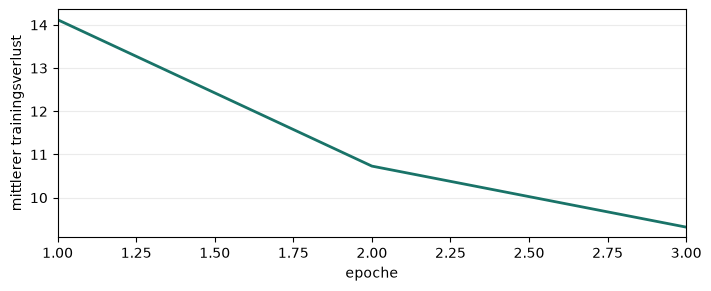

In [4]:
batches = DataLoader(train, batch_size=8, shuffle=True, collate_fn=list,
                     generator=torch.Generator().manual_seed(seed))
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=0.0001)
history = []
model.train()
for epoch in range(1, 4):
    epoch_loss = 0.0
    for batch in batches:
        images, targets = zip(*batch)
        optimizer.zero_grad(set_to_none=True)
        losses = model(list(images), list(targets))
        loss = sum(losses.values())
        if not loss.isfinite():
            raise ValueError(f"ungültiger verlust in epoche {epoch}")
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item() * len(batch)
    history.append(epoch_loss / len(train))

fig, ax = plt.subplots(figsize=(7, 2.8), layout="constrained")
ax.plot(range(1, len(history) + 1), history, color="#197368", linewidth=2)
ax.set(xlabel="epoche", ylabel="mittlerer trainingsverlust", xlim=(1, len(history)))
ax.grid(axis="y", alpha=0.25)
plt.show()

## Auswertung

Die Tabelle zeigt die vier AP50-Werte und ihren Mittelwert. Bei Truck und Cyclist enthält die Validierung jeweils nur eine einzelne Box.

In [5]:
after = evaluate(model)
display(pd.DataFrame({"vor training": before, "nach training": after}).round(4))

checkpoint = Path("runs/kitti/cnn/ssdlite320.pt")
checkpoint.parent.mkdir(parents=True, exist_ok=True)
torch.save({
    "model": model.state_dict(),
    "class_names": {i + 1: name for i, name in enumerate(CLASSES)},
    "train_ids": train_ids,
    "val_ids": val_ids,
}, checkpoint)
print(f"gewichte: {checkpoint}")

,vor training,nach training
Car,0.0,0.0004
Truck,0.0,0.0000
Cyclist,0.0,0.0000
Pedestrian,0.0,0.0000
map50,0.0,0.0001


gewichte: runs/kitti/cnn/ssdlite320.pt
